## Author: Gabriel Vance
## Class: DSC550 - Data Mining
## Professor: Dr. Brett Werner
## Date: November 15, 2025

# Purpose: This notebook performs the tasks outlined in Week 9 & 10 Assignment - TSA Complaints. For this exercise we will be utilizing python/notebooks to visualize datasets pertaining to TSA complaints.


In [45]:
# Imports
import pandas as pd
import numpy as np

#### First we will read in data

In [46]:
iata_icao  = pd.read_csv('iata-icao.csv')
complaints_by_subcategory  = pd.read_csv('complaints-by-subcategory.csv')
iata_complaints_by_category_icao  = pd.read_csv('complaints-by-category.csv')
complaints_by_airport  = pd.read_csv('complaints-by-airport.csv')

In [ ]:
# Aggregate complaints per airport
complaints_airport_totals = (
    complaints_by_airport
    .groupby('airport', as_index=False)['count']
    .sum()
    .rename(columns={'count': 'total_complaints'})
)

# Join with location data
airports_with_complaints = complaints_airport_totals.merge(
    iata_icao,
    left_on='airport',  # IATA code from complaints
    right_on='iata',    # IATA from iata_icao
    how='left'
)

# --- NEW: filter to US and keep top airports by complaints ---

# Keep only US airports and valid coordinates
us_airports = (
    airports_with_complaints
    [airports_with_complaints['country_code'] == 'US']
    .dropna(subset=['latitude', 'longitude'])
)

# Choose how many top airports to show
top_10 = 10  # change to 10, 50, etc. if you want

us_top_airports = (
    us_airports
    .sort_values('total_complaints', ascending=False)
    .head(top_10)
)

import plotly.express as px

fig = px.scatter_geo(
    us_top_airports,
    lat='latitude',
    lon='longitude',
    scope='usa',                          # focus on USA only
    projection='albers usa',
    size='total_complaints',
    color='total_complaints',             # color by complaints too
    hover_name='airport_y',               # airport name from iata_icao
    hover_data=['iata', 'total_complaints', 'region_name'],
    title=f'Top {top_10} US Airports by Total Complaints'
)
fig.show()


In [ ]:
# Aggregate complaints per airport
complaints_airport_totals = (
    complaints_by_airport
    .groupby('airport', as_index=False)['count']
    .sum()
    .rename(columns={'count': 'total_complaints'})
)

# Join with location data
airports_with_complaints = complaints_airport_totals.merge(
    iata_icao,
    left_on='airport',  # IATA code from complaints
    right_on='iata',    # IATA from iata_icao
    how='left'
)


# Keep only US airports and valid coordinates
us_airports = (
    airports_with_complaints
    [airports_with_complaints['country_code'] == 'US']
    .dropna(subset=['latitude', 'longitude'])
)

# Choose how many top airports to show
bottom_25 = 10

us_top_airports = (
    us_airports
    .sort_values('total_complaints', ascending=False)
    .tail(bottom_25)
)

import plotly.express as px

fig = px.scatter_geo(
    us_top_airports,
    lat='latitude',
    lon='longitude',
    scope='usa',                          # focus on USA only
    projection='albers usa',
    size='total_complaints',
    color='total_complaints',             # color by complaints too
    hover_name='airport_y',               # airport name from iata_icao
    hover_data=['iata', 'total_complaints', 'region_name'],
    title=f'Top {bottom_25} US Airports by Total Complaints'
)
fig.show()


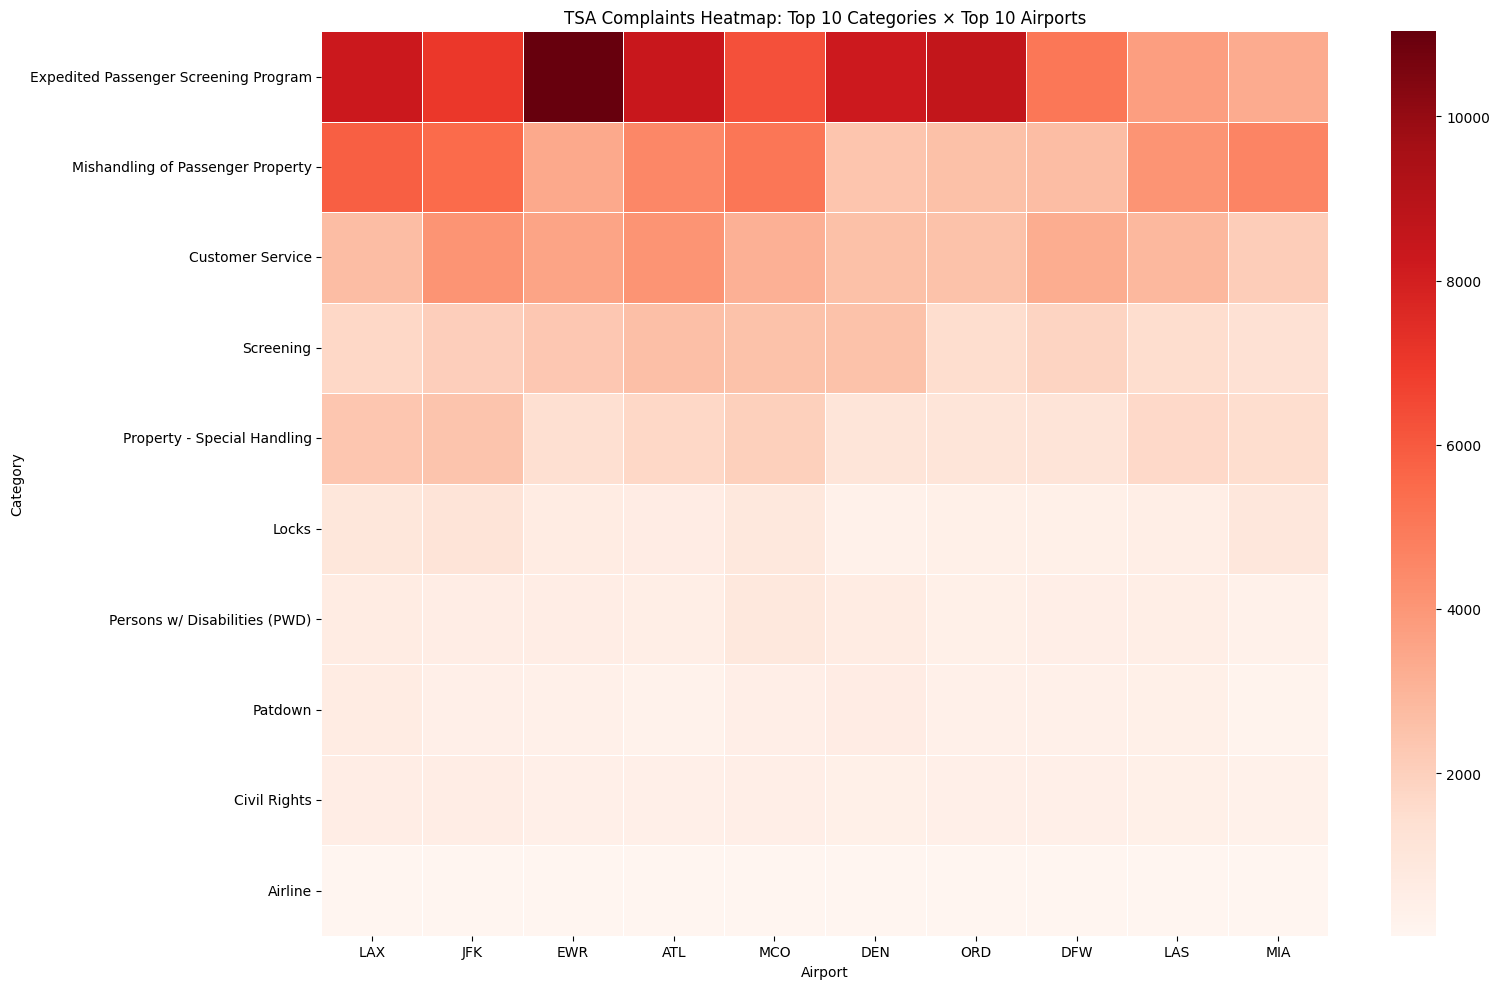

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

# ---- 1. Find top 10 airports ----
airport_totals = (
    iata_complaints_by_category_icao
    .groupby('airport')['count']
    .sum()
    .sort_values(ascending=False)
)

top_10_airports = airport_totals.head(10).index

# ---- 2. Find top 10 categories ----
category_totals = (
    iata_complaints_by_category_icao
    .groupby('category')['count']
    .sum()
    .sort_values(ascending=False)
)

top_10_categories = category_totals.head(10).index

# ---- 3. Filter original data to top airports & top categories ----
top_data = iata_complaints_by_category_icao[
    (iata_complaints_by_category_icao['airport'].isin(top_10_airports)) &
    (iata_complaints_by_category_icao['category'].isin(top_10_categories))
]

# ---- 4. Create heatmap matrix ----
heatmap_data = (
    top_data
    .groupby(['category', 'airport'])['count']
    .sum()
    .unstack(fill_value=0)
    .reindex(index=top_10_categories, columns=top_10_airports)
)

plt.figure(figsize=(16, 10))
sns.heatmap(heatmap_data, cmap='Reds', linewidths=0.5)
plt.title('TSA Complaints Heatmap: Top 10 Categories × Top 10 Airports')
plt.xlabel('Airport')
plt.ylabel('Category')
plt.tight_layout()
plt.show()


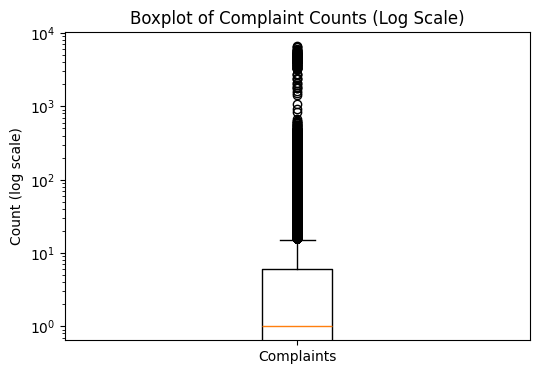

In [57]:
import pandas as pd
from io import StringIO

import matplotlib.pyplot as plt



df_box = complaints_by_airport

plt.figure(figsize=(6, 4))
plt.boxplot(df_box['count'], vert=True)
plt.yscale('log')

plt.title('Boxplot of Complaint Counts (Log Scale)')
plt.ylabel('Count (log scale)')
plt.xticks([1], ['Complaints'])
plt.show()
